In [1]:
!pip install -q --no-cache-dir --force-reinstall --no-deps git+https://github.com/RayenSansa03/aeroguard.git@main

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
from google.colab import drive
drive.mount("/content/drive")

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score

from aeroguard.augmentation import gaussienne, plis_famille_rare, rogner, smote_simple
from aeroguard.autoencodeurs import standardiser, statistiques_features
from aeroguard.donnees_ml import preparer_xy
from aeroguard.gan import creer_discriminateur, creer_generateur, entrainer_gan, generer
from aeroguard.modeles import creer_xgboost

DOSSIER = "/content/drive/MyDrive/aeroguard"
FAMILLE_RARE = "fan"
EPOCHS_GAN = 1500
SEUIL = 0.5

vols = pd.read_parquet(f"{DOSSIER}/data/processed/vols_ncmapss.parquet")
morceaux = [preparer_xy(vols, g) for g in ("train", "val")]      # le TEST reste fermé (6.6)
X_pool = pd.concat([X for X, _ in morceaux])
y_pool = pd.concat([y for _, y in morceaux]).to_numpy()
moteurs = vols.loc[X_pool.index, "moteur"].to_numpy()
rul = vols.loc[X_pool.index, "RUL"].to_numpy()
familles = vols.loc[X_pool.index, "famille"].astype(str).to_numpy()

plis = plis_famille_rare(moteurs, familles, FAMILLE_RARE, graine=42)
print(f"{len(X_pool)} vols, {len(np.unique(moteurs))} moteurs, {len(plis)} plis")
for numero, masque in enumerate(plis):
    fan = np.unique(moteurs[masque & (familles == FAMILLE_RARE)])
    print(f"  pli {numero} : {len(np.unique(moteurs[masque]))} moteurs évalués (fan : {fan}), {masque.sum()} vols")

Mounted at /content/drive
4535 vols, 60 moteurs, 6 plis
  pli 0 : 10 moteurs évalués (fan : ['DS04_1']), 826 vols
  pli 1 : 10 moteurs évalués (fan : ['DS04_2']), 765 vols
  pli 2 : 10 moteurs évalués (fan : ['DS04_3']), 854 vols
  pli 3 : 10 moteurs évalués (fan : ['DS04_4']), 689 vols
  pli 4 : 10 moteurs évalués (fan : ['DS04_5']), 719 vols
  pli 5 : 10 moteurs évalués (fan : ['DS04_6']), 682 vols


In [3]:
METHODES = ["sans_ajout", "smote", "gaussienne", "gan_brut", "gan_rogne"]


def synthetiques(X_rare_std, n, graine):
    """Les 4 jeux de faux vols standardisés d'un pli, à partir des seuls vols rares d'entraînement."""
    generateur = creer_generateur(X_rare_std.shape[1])
    discriminateur = creer_discriminateur(X_rare_std.shape[1])
    entrainer_gan(generateur, discriminateur, X_rare_std, epochs=EPOCHS_GAN, taille_lot=64,
                  afficher_tous_les=0, graine=graine)
    faux_gan = generer(generateur, n, graine=graine)
    return {
        "smote": smote_simple(X_rare_std, n, graine=graine),
        "gaussienne": gaussienne(X_rare_std, n, graine=graine),
        "gan_brut": faux_gan,
        "gan_rogne": rogner(faux_gan, X_rare_std),
    }

In [4]:
lignes = []
debut = time.perf_counter()
for numero, evaluation in enumerate(plis):
    app = ~evaluation

    # 1) Les vrais vols usés de la famille rare, dans l'ENTRAÎNEMENT du pli uniquement
    rare_app = app & (familles == FAMILLE_RARE) & (y_pool == 1)
    X_rare = X_pool[rare_app].fillna(X_pool[app].median())
    moy, ec = statistiques_features(X_rare.to_numpy(dtype="float64"))
    ec = np.where(np.asarray(ec) > 0, ec, 1.0)
    X_rare_std = standardiser(X_rare.to_numpy(dtype="float64"), moy, ec).astype("float32")
    faux_std = synthetiques(X_rare_std, len(X_rare), graine=numero)

    # 2) Ce qu'on mesure sur l'évaluation du pli (vrais vols uniquement)
    y_eval = y_pool[evaluation]
    fan_eval = familles[evaluation] == FAMILLE_RARE
    critique_fan = fan_eval & (rul[evaluation] <= 10)

    for methode in METHODES:
        X_app, y_app = X_pool[app], y_pool[app]
        if methode != "sans_ajout":
            faux = pd.DataFrame(faux_std[methode] * ec + moy, columns=X_pool.columns)
            X_app = pd.concat([X_app, faux], ignore_index=True)
            y_app = np.r_[y_app, np.ones(len(faux))]
        xgb = creer_xgboost("cpu", early_stopping_rounds=None, n_estimators=411)
        xgb.fit(X_app, y_app)
        probas = xgb.predict_proba(X_pool[evaluation])[:, 1]
        lignes.append({
            "pli": numero, "methode": methode,
            "pr_auc_global": average_precision_score(y_eval, probas),
            "pr_auc_fan": average_precision_score(y_eval[fan_eval], probas[fan_eval]),
            "rappel_critique_fan": float((probas[critique_fan] >= SEUIL).mean()),
        })
    print(f"pli {numero} terminé ({len(X_rare)} vols rares réels + autant de faux) "
          f"— {time.perf_counter() - debut:.0f} s")

resultats = pd.DataFrame(lignes)
resultats.to_csv(f"{DOSSIER}/results/65_augmentation_plis.csv", index=False)
resultats.pivot(index="pli", columns="methode", values="pr_auc_fan")[METHODES].round(4)

pli 0 terminé (341 vols rares réels + autant de faux) — 86 s
pli 1 terminé (350 vols rares réels + autant de faux) — 153 s
pli 2 terminé (328 vols rares réels + autant de faux) — 216 s
pli 3 terminé (353 vols rares réels + autant de faux) — 282 s
pli 4 terminé (323 vols rares réels + autant de faux) — 345 s
pli 5 terminé (340 vols rares réels + autant de faux) — 410 s


methode,sans_ajout,smote,gaussienne,gan_brut,gan_rogne
pli,,,,,
0,0.9670,0.9705,0.9684,0.9719,0.9684
1,0.9909,0.9887,0.9821,0.9871,0.9867
2,0.9663,0.9692,0.9688,0.9699,0.9721
3,0.9744,0.9762,0.9720,0.9701,0.9742
4,0.9903,0.9935,0.9909,0.9912,0.9933
5,0.9823,0.9830,0.9827,0.9800,0.9795


In [5]:
base = resultats[resultats["methode"] == "sans_ajout"].set_index("pli")
bilan = []
for methode in METHODES[1:]:
    r = resultats[resultats["methode"] == methode].set_index("pli")
    gain_fan = r["pr_auc_fan"] - base["pr_auc_fan"]
    bilan.append({
        "methode": methode,
        "gain_fan_moyen": gain_fan.mean(),
        "plis_gagnes": int((gain_fan > 0).sum()),
        "gain_global_moyen": (r["pr_auc_global"] - base["pr_auc_global"]).mean(),
        "gain_rappel_critique": (r["rappel_critique_fan"] - base["rappel_critique_fan"]).mean(),
    })
bilan = pd.DataFrame(bilan).set_index("methode")
bilan["utile"] = ((bilan["gain_fan_moyen"] > 0) & (bilan["plis_gagnes"] >= 5)
                  & (bilan["gain_global_moyen"] >= -0.005))
bilan.to_csv(f"{DOSSIER}/results/65_augmentation_bilan.csv")

print("Référence sans ajout (moyenne sur 6 plis) :",
      base[["pr_auc_global", "pr_auc_fan", "rappel_critique_fan"]].mean().round(4).to_dict())
bilan.round(4)

Référence sans ajout (moyenne sur 6 plis) : {'pr_auc_global': 0.9837, 'pr_auc_fan': 0.9785, 'rappel_critique_fan': 1.0}


,gain_fan_moyen,plis_gagnes,gain_global_moyen,gain_rappel_critique,utile
methode,,,,,
smote,0.0017,5,0.0003,0.0,True
gaussienne,-0.0011,4,-0.0001,0.0,False
gan_brut,-0.0002,3,-0.0000,0.0,False
gan_rogne,0.0005,3,0.0004,0.0,False


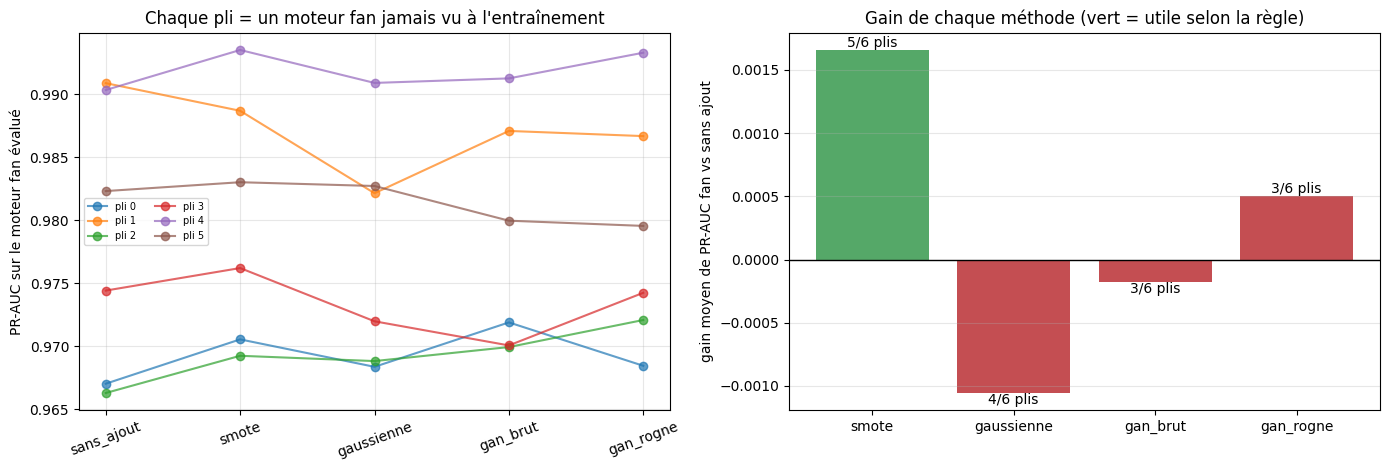

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))

tableau = resultats.pivot(index="pli", columns="methode", values="pr_auc_fan")[METHODES]
for pli, ligne in tableau.iterrows():
    ax1.plot(METHODES, ligne.values, marker="o", alpha=0.7, label=f"pli {pli}")
ax1.set_ylabel("PR-AUC sur le moteur fan évalué")
ax1.set_title("Chaque pli = un moteur fan jamais vu à l'entraînement")
ax1.tick_params(axis="x", rotation=20)
ax1.legend(fontsize=7, ncol=2)
ax1.grid(alpha=0.3)

couleurs = ["#55A868" if u else "#C44E52" for u in bilan["utile"]]
ax2.bar(bilan.index, bilan["gain_fan_moyen"], color=couleurs)
for position, (gain, gagnes) in enumerate(zip(bilan["gain_fan_moyen"], bilan["plis_gagnes"])):
    ax2.text(position, gain, f"{gagnes}/6 plis", ha="center", va="bottom" if gain >= 0 else "top")
ax2.axhline(0, color="black", linewidth=1)
ax2.set_ylabel("gain moyen de PR-AUC fan vs sans ajout")
ax2.set_title("Gain de chaque méthode (vert = utile selon la règle)")
ax2.grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(f"{DOSSIER}/results/figures/65_gan_contre_smote.png", dpi=150, bbox_inches="tight")
plt.show()